# Part 1 · Notebook 2: Models and results

**Goal:** find the best model for EuroSAT and understand *why* it wins, by testing the hypotheses of
[notebook 1](01_eurosat_exploration.ipynb).

| Model | Test accuracy (95 % interval) | Tests |
|---|---|---|
| **ResNet-18, Sentinel-2 pretrained, 13 bands** | **98.98 %** (98.7–99.2) | H3: pretraining |
| Small CNN, 13 bands | 98.48 % (98.1–98.8) | H2: spatial pattern |
| Small CNN, RGB | 97.76 % (97.4–98.2) | H4: bands, same network |
| ResNet-18, ImageNet pretrained, RGB | 97.61 % (97.2–98.0) | H4: the guide's comparison |
| Random Forest + texture | 90.07 % (89.3–90.9) | H2: rough texture |
| Random Forest, tile averages | 83.69 % (82.8–84.7) | H1: averages only |

**Key findings**

- Seeing the pixels, not only the average colour, brings most of the accuracy: +15 points, mostly on Highway
  and Residential.
- With the same network, 13 bands beat RGB by 0.7 points (paired test p = 0.001), mostly on PermanentCrop
  and HerbaceousVegetation.
- Sentinel-2 pretraining adds 0.5 points (p = 0.003) and reaches 96 % after one epoch instead of eleven.
  ImageNet pretraining adds nothing (p = 0.60).

**Protocol.** Official splits (16,200 / 5,400 / 5,400 tiles). Choices are made on validation only; each
model is tested once, at the end; runs are logged in MLflow. The small CNN on RGB was added so that one
comparison changes *only* the bands: the two ResNets differ both in bands and in pretraining.

In [ ]:
import os
import warnings

# Quieter output. Set before the imports: the libraries print these notices when imported.
os.environ["HF_HUB_VERBOSITY"] = "error"  # no Hugging Face notice when downloading ImageNet weights
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*LeafSpec.*")
warnings.filterwarnings("ignore", message=".*Checkpoint directory.*exists and is not empty.*")

import logging
import shutil
import sys

import lightning as L
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import MLFlowLogger
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from sentinel_agri.config import (
    BANDS_BY_WAVELENGTH,
    EUROSAT_BANDS,
    EUROSAT_CLASSES,
    FIGURES_DIR,
    MLFLOW_TRACKING_URI,
    MODELS_DIR,
    RGB_BANDS,
    ROOT,
)
from sentinel_agri.data import band_stats, eurosat, load_tile_features, make_loaders, to_rgb
from sentinel_agri.evaluation import plot_confusion_matrix, predict, scores, top_confusions
from sentinel_agri.models import EpochSummary, LitClassifier, SmallCNN, resnet18_imagenet, resnet18_sentinel2

for name in ("lightning.pytorch", "lightning.fabric"):  # set after importing lightning
    logging.getLogger(name).setLevel(logging.WARNING)

SEED = 42
EXPERIMENT = "part1-eurosat"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

L.seed_everything(SEED)
torch.set_float32_matmul_precision("high")  # faster matrix products on the GPU's tensor cores
sns.set_theme(style="whitegrid", context="notebook")
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(EXPERIMENT)
print("Device:", DEVICE)

Device: cuda


In [2]:
features = load_tile_features()  # cached table from notebook 1
splits = {s: features[features.split == s] for s in ("train", "val", "test")}

# Everything each model produces is collected here, then compared in sections 5 and 6.
models = {}  # name -> trained model
run_ids = {}  # name -> MLflow run id
val_scores = {}  # name -> validation metrics

## 1. Baseline: Random Forest on tile averages

A fast, robust baseline on 14 numbers per tile (13 band means and NDVI). It sets the bar for the deep
models.

In [3]:
RF_FEATURES = [f"mean_{b}" for b in EUROSAT_BANDS] + ["ndvi_mean"]


def fit_random_forest(name, columns):
    with mlflow.start_run(run_name=name) as run:
        rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED)
        rf.fit(splits["train"][columns], splits["train"]["label"])
        val = scores(splits["val"]["label"], rf.predict(splits["val"][columns]))
        mlflow.log_params({"model": "random_forest", "n_estimators": 500, "n_features": len(columns)})
        mlflow.log_metrics({f"val_{k}": v for k, v in val.items()})
    models[name], run_ids[name], val_scores[name] = rf, run.info.run_id, val
    print(f"{name}: val accuracy {val['accuracy']:.4f}, macro F1 {val['macro_f1']:.4f}")
    return rf


rf = fit_random_forest("Random Forest", RF_FEATURES)

Random Forest: val accuracy 0.8372, macro F1 0.8271


Which features does it use? Permutation importance: the drop in validation accuracy when one feature is shuffled.

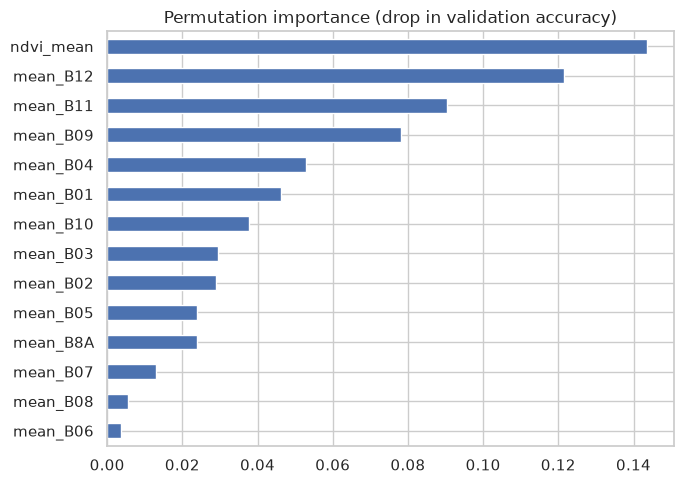

In [4]:
perm = permutation_importance(
    rf, splits["val"][RF_FEATURES], splits["val"]["label"], n_repeats=5, random_state=SEED, n_jobs=-1
)
importance = pd.Series(perm.importances_mean, index=RF_FEATURES).sort_values()
importance.plot.barh(figsize=(7, 5), title="Permutation importance (drop in validation accuracy)")
plt.tight_layout()

**What it shows**

- 83.7 % validation accuracy.
- NDVI and the short-wave infrared (B12, B11) matter most: two of the top three features lie outside RGB.
- The atmospheric bands B09 and B10 rank 4th and 7th. They likely carry hints about acquisition
  conditions, a shortcut that would not hold on new images.

### Random Forest + texture

The same model, plus the within-tile standard deviation of each band.

In [5]:
RF_TEXTURE_FEATURES = RF_FEATURES + [f"std_{b}" for b in EUROSAT_BANDS] + ["ndvi_std"]
rf_texture = fit_random_forest("Random Forest + texture", RF_TEXTURE_FEATURES)

Random Forest + texture: val accuracy 0.8952, macro F1 0.8895


**What it shows**

- Validation accuracy rises from 83.7 to 89.5 %, mostly on Highway and Residential (section 6): a first sign for H2.

## 2. Training setup for the deep models

All four networks share the same training code: cross-entropy loss, AdamW with a cosine schedule, random
flips and 90° rotations (a satellite tile has no "up"), and the checkpoint with the best validation accuracy
is kept.

Each model gets the input scaling it needs: per-band standardisation on training pixels for the small CNNs,
reflectance ÷ 10,000 for the Sentinel-2 weights (as during their pretraining), photo-like scaling for the
ImageNet weights. The Sentinel-2 weights also expect the bands in wavelength order (B8A after B08), so the
loaders reorder them.

In [6]:
cnn_mean_13, cnn_std_13 = band_stats(splits["train"], BANDS_BY_WAVELENGTH)
cnn_mean_rgb, cnn_std_rgb = band_stats(splits["train"], RGB_BANDS)

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # R, G, B
RGB_SCALE = 3000

pd.DataFrame({"mean": cnn_mean_13, "std": cnn_std_13}, index=BANDS_BY_WAVELENGTH).round(1)

,mean,std
B01,1354.4,245.7
B02,1118.2,333.0
B03,1042.9,395.1
B04,947.6,593.8
B05,1199.5,566.4
B06,1999.8,861.2
B07,2369.2,1086.7
B08,2296.8,1118.0
B8A,2594.1,1231.6
B09,732.1,404.9


In [7]:
def train_deep(name, net, bands, mean, std, lr, max_epochs, batch_size=128):
    """Train with the protocol above, reload the best epoch, return the model on DEVICE."""
    loaders = make_loaders(bands, batch_size=batch_size)
    lit = LitClassifier(net, mean=mean, std=std, lr=lr)
    logger = MLFlowLogger(experiment_name=EXPERIMENT, tracking_uri=MLFLOW_TRACKING_URI, run_name=name)
    logger.log_hyperparams({"model": name, "bands": ",".join(bands), "batch_size": batch_size, "max_epochs": max_epochs})
    checkpoint_dir = MODELS_DIR / "checkpoints" / name.replace(" ", "_")
    shutil.rmtree(checkpoint_dir, ignore_errors=True)  # otherwise checkpoints of earlier runs accumulate
    checkpoint = ModelCheckpoint(dirpath=checkpoint_dir, monitor="val_acc", mode="max", save_top_k=1)
    trainer = L.Trainer(
        max_epochs=max_epochs,
        accelerator="auto",
        precision="16-mixed" if DEVICE == "cuda" else "32",
        logger=logger,
        callbacks=[checkpoint, EpochSummary()],
        enable_progress_bar=False,  # replaced by EpochSummary: one line per epoch
        enable_model_summary=False,
        log_every_n_steps=20,
    )
    trainer.fit(lit, loaders["train"], loaders["val"])

    best = LitClassifier.load_from_checkpoint(checkpoint.best_model_path, net=net).to(DEVICE)
    y, probs = predict(best, loaders["val"])
    val = scores(y, probs.argmax(axis=1))
    mlflow.MlflowClient().log_metric(logger.run_id, "best_val_macro_f1", val["macro_f1"])

    models[name], run_ids[name], val_scores[name] = best, logger.run_id, val
    print(f"{name}: best epoch {torch.load(checkpoint.best_model_path, weights_only=False)['epoch']}, "
          f"val accuracy {val['accuracy']:.4f}, macro F1 {val['macro_f1']:.4f}")
    return best


def plot_history(name):
    """Training and validation curves of one run, read back from MLflow."""
    client = mlflow.MlflowClient()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, metric in zip(axes, ["loss", "acc"]):
        for stage in ["train", "val"]:
            history = client.get_metric_history(run_ids[name], f"{stage}_{metric}")
            ax.plot([m.step for m in history], [m.value for m in history], marker=".", label=stage)
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("step")
        ax.legend()
    plt.tight_layout()

## 3. Small CNN from scratch

About 1.2 million parameters, trained from random weights on 13 bands, then on RGB only.

epoch  1/30 | train loss 0.631 acc 0.794 | val loss 0.593 acc 0.805 |   47 s *
epoch  2/30 | train loss 0.359 acc 0.883 | val loss 0.430 acc 0.860 |   43 s *
epoch  3/30 | train loss 0.290 acc 0.905 | val loss 0.239 acc 0.923 |   33 s *
epoch  4/30 | train loss 0.243 acc 0.922 | val loss 0.265 acc 0.910 |   26 s
epoch  5/30 | train loss 0.218 acc 0.928 | val loss 0.214 acc 0.931 |   27 s *
epoch  6/30 | train loss 0.189 acc 0.938 | val loss 0.147 acc 0.953 |   27 s *
epoch  7/30 | train loss 0.173 acc 0.944 | val loss 0.199 acc 0.935 |   25 s
epoch  8/30 | train loss 0.167 acc 0.947 | val loss 0.130 acc 0.958 |   24 s *
epoch  9/30 | train loss 0.144 acc 0.953 | val loss 0.127 acc 0.961 |   28 s *
epoch 10/30 | train loss 0.129 acc 0.957 | val loss 0.173 acc 0.946 |   34 s
epoch 11/30 | train loss 0.127 acc 0.958 | val loss 0.101 acc 0.969 |   27 s *
epoch 12/30 | train loss 0.116 acc 0.961 | val loss 0.096 acc 0.971 |   26 s *
epoch 13/30 | train loss 0.105 acc 0.966 | val loss 0.107 

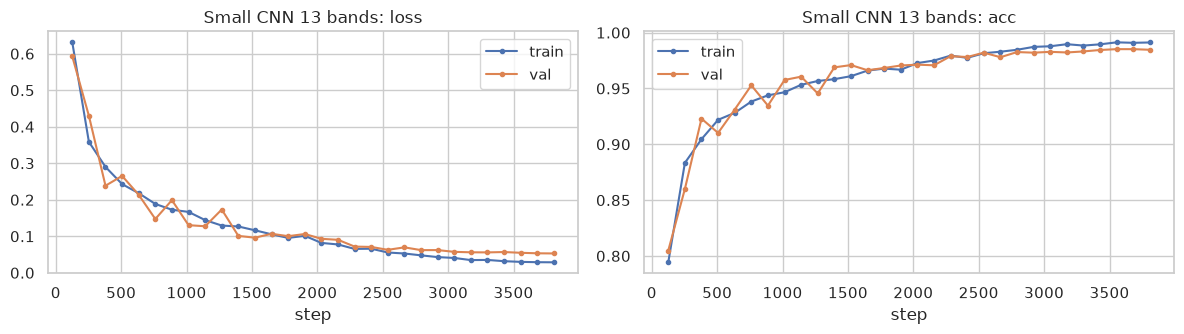

In [8]:
train_deep("Small CNN 13 bands", SmallCNN(in_channels=13), BANDS_BY_WAVELENGTH, cnn_mean_13, cnn_std_13, lr=1e-3, max_epochs=30)
plot_history("Small CNN 13 bands")

epoch  1/30 | train loss 0.912 acc 0.679 | val loss 0.700 acc 0.749 |   27 s *
epoch  2/30 | train loss 0.611 acc 0.788 | val loss 0.766 acc 0.736 |   22 s
epoch  3/30 | train loss 0.472 acc 0.840 | val loss 0.526 acc 0.828 |   23 s *
epoch  4/30 | train loss 0.397 acc 0.864 | val loss 0.836 acc 0.725 |   23 s
epoch  5/30 | train loss 0.349 acc 0.884 | val loss 0.592 acc 0.790 |   23 s
epoch  6/30 | train loss 0.291 acc 0.903 | val loss 0.286 acc 0.904 |   24 s *
epoch  7/30 | train loss 0.256 acc 0.913 | val loss 0.321 acc 0.883 |   26 s
epoch  8/30 | train loss 0.230 acc 0.923 | val loss 0.269 acc 0.912 |   24 s *
epoch  9/30 | train loss 0.208 acc 0.930 | val loss 0.221 acc 0.928 |   22 s *
epoch 10/30 | train loss 0.184 acc 0.938 | val loss 0.194 acc 0.931 |   24 s *
epoch 11/30 | train loss 0.175 acc 0.939 | val loss 0.228 acc 0.924 |   25 s
epoch 12/30 | train loss 0.170 acc 0.943 | val loss 0.247 acc 0.919 |   21 s
epoch 13/30 | train loss 0.149 acc 0.949 | val loss 0.182 acc 0.

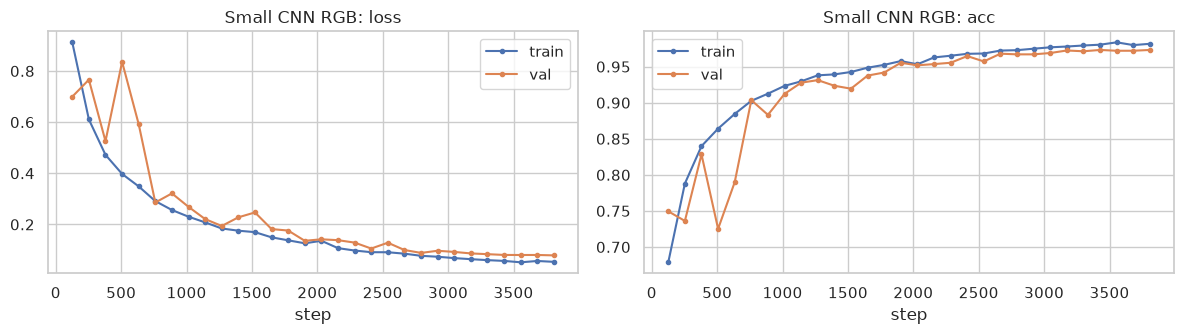

In [9]:
train_deep("Small CNN RGB", SmallCNN(in_channels=3), RGB_BANDS, cnn_mean_rgb, cnn_std_rgb, lr=1e-3, max_epochs=30)
plot_history("Small CNN RGB")

**What it shows**

- 13 bands: 98.5 % on validation; RGB: 97.3 %. Train and validation curves stay close: no overfitting.
- Both reach their best score in the last epochs, so longer training might add a little. (The line under
  each log counts epochs from 0.)

## 4. Pretrained ResNet-18

The same ResNet-18, starting from weights learned on about a million Sentinel-2 images (13 bands, the same
kind of data as EuroSAT) or on ImageNet photos (RGB), fine-tuned for 15 epochs.

epoch  1/15 | train loss 0.492 acc 0.931 | val loss 0.151 acc 0.962 |   27 s *
epoch  2/15 | train loss 0.138 acc 0.963 | val loss 0.304 acc 0.908 |   23 s
epoch  3/15 | train loss 0.095 acc 0.974 | val loss 0.093 acc 0.973 |   24 s *
epoch  4/15 | train loss 0.073 acc 0.978 | val loss 0.088 acc 0.974 |   22 s *
epoch  5/15 | train loss 0.066 acc 0.981 | val loss 0.127 acc 0.960 |   23 s
epoch  6/15 | train loss 0.053 acc 0.984 | val loss 0.082 acc 0.976 |   23 s *
epoch  7/15 | train loss 0.040 acc 0.988 | val loss 0.071 acc 0.978 |   23 s *
epoch  8/15 | train loss 0.032 acc 0.990 | val loss 0.068 acc 0.979 |   25 s *
epoch  9/15 | train loss 0.027 acc 0.992 | val loss 0.048 acc 0.986 |   29 s *
epoch 10/15 | train loss 0.019 acc 0.995 | val loss 0.049 acc 0.985 |   31 s
epoch 11/15 | train loss 0.019 acc 0.994 | val loss 0.044 acc 0.986 |   27 s *
epoch 12/15 | train loss 0.013 acc 0.997 | val loss 0.042 acc 0.988 |   25 s *
epoch 13/15 | train loss 0.011 acc 0.997 | val loss 0.041 

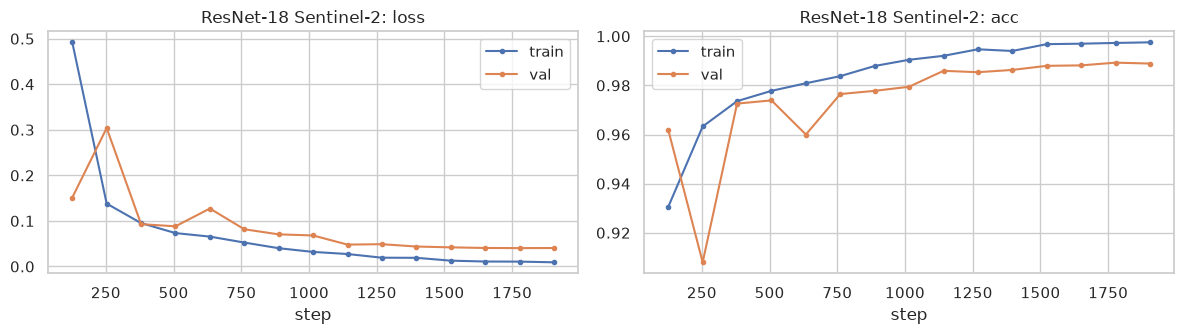

In [10]:
train_deep("ResNet-18 Sentinel-2", resnet18_sentinel2(), BANDS_BY_WAVELENGTH, [0.0] * 13, [10000.0] * 13, lr=3e-4, max_epochs=15)
plot_history("ResNet-18 Sentinel-2")

epoch  1/15 | train loss 0.975 acc 0.745 | val loss 0.353 acc 0.898 |   26 s *
epoch  2/15 | train loss 0.222 acc 0.930 | val loss 0.199 acc 0.936 |   21 s *
epoch  3/15 | train loss 0.156 acc 0.947 | val loss 0.158 acc 0.947 |   22 s *
epoch  4/15 | train loss 0.125 acc 0.959 | val loss 0.133 acc 0.955 |   23 s *
epoch  5/15 | train loss 0.106 acc 0.963 | val loss 0.106 acc 0.964 |   22 s *
epoch  6/15 | train loss 0.086 acc 0.969 | val loss 0.096 acc 0.968 |   25 s *
epoch  7/15 | train loss 0.086 acc 0.970 | val loss 0.112 acc 0.961 |   21 s
epoch  8/15 | train loss 0.069 acc 0.976 | val loss 0.088 acc 0.971 |   22 s *
epoch  9/15 | train loss 0.068 acc 0.978 | val loss 0.084 acc 0.973 |   23 s *
epoch 10/15 | train loss 0.057 acc 0.981 | val loss 0.102 acc 0.966 |   23 s
epoch 11/15 | train loss 0.055 acc 0.982 | val loss 0.079 acc 0.974 |   23 s *
epoch 12/15 | train loss 0.052 acc 0.983 | val loss 0.075 acc 0.975 |   24 s *
epoch 13/15 | train loss 0.049 acc 0.983 | val loss 0.07

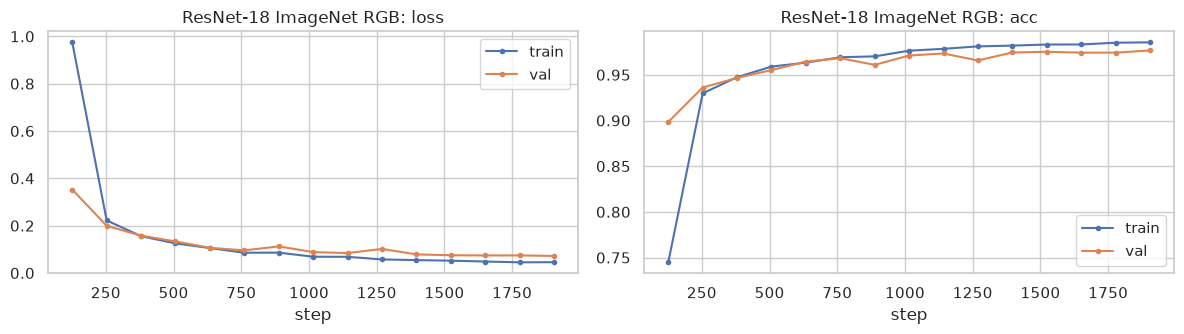

In [11]:
train_deep(
    "ResNet-18 ImageNet RGB",
    resnet18_imagenet(),
    RGB_BANDS,
    [RGB_SCALE * m for m in IMAGENET_MEAN],
    [RGB_SCALE * s for s in IMAGENET_STD],
    lr=3e-4,
    max_epochs=15,
)
plot_history("ResNet-18 ImageNet RGB")

**What it shows**

- The Sentinel-2 ResNet reaches 96.2 % after one epoch, a level the small CNN needed 11 epochs to pass, and
  ends at 98.9 %.
- The ImageNet ResNet starts lower (89.8 %) and ends at 97.7 %, barely above the small RGB CNN.

## 5. Validation summary

No setting was changed after seeing these scores, so the test set stays unbiased.

In [12]:
val_table = pd.DataFrame(val_scores).T[["accuracy", "macro_f1"]].sort_values("accuracy", ascending=False)
val_table.style.format("{:.4f}")

,accuracy,macro_f1
ResNet-18 Sentinel-2,0.9893,0.9888
Small CNN 13 bands,0.9850,0.9843
ResNet-18 ImageNet RGB,0.9767,0.9759
Small CNN RGB,0.9731,0.9723
Random Forest + texture,0.8952,0.8895
Random Forest,0.8372,0.8271


## 6. Test set

Each model is tested once. The 95 % interval (bootstrap over the 5,400 tiles) shows how much a score would
move with another test set of the same size.

In [13]:
test_loaders = {"13": make_loaders(BANDS_BY_WAVELENGTH)["test"], "rgb": make_loaders(RGB_BANDS)["test"]}
test_predictions = {}  # name -> (y_true, y_pred, probabilities)

for name, model in models.items():
    if isinstance(model, RandomForestClassifier):
        columns = RF_FEATURES if name == "Random Forest" else RF_TEXTURE_FEATURES
        y = splits["test"]["label"].to_numpy()
        probs = model.predict_proba(splits["test"][columns])
    else:
        y, probs = predict(model, test_loaders["rgb" if "RGB" in name else "13"])
    test_predictions[name] = (y, probs.argmax(axis=1), probs)

# Every model must see the test tiles in the same order, or the comparisons below are meaningless.
reference = next(iter(test_predictions.values()))[0]
assert all((y == reference).all() for y, _, _ in test_predictions.values())

In [14]:
def bootstrap_accuracy_ci(y_true, y_pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (y_true == y_pred).astype(float)
    samples = rng.choice(correct, size=(n, len(correct)), replace=True).mean(axis=1)
    return np.percentile(samples, [2.5, 97.5])


rows = {}
for name, (y, pred, _) in test_predictions.items():
    s = scores(y, pred)
    low, high = bootstrap_accuracy_ci(y, pred)
    rows[name] = {"accuracy": s["accuracy"], "95% CI": f"{low:.3f} – {high:.3f}", "macro_f1": s["macro_f1"]}
    mlflow.MlflowClient().log_metric(run_ids[name], "test_accuracy", s["accuracy"])
    mlflow.MlflowClient().log_metric(run_ids[name], "test_macro_f1", s["macro_f1"])

results = pd.DataFrame(rows).T.sort_values("accuracy", ascending=False)
results.to_csv(ROOT / "reports" / "part1_results.csv")
results.style.format({"accuracy": "{:.4f}", "macro_f1": "{:.4f}"})

,accuracy,95% CI,macro_f1
ResNet-18 Sentinel-2,0.9898,0.987 – 0.992,0.9897
Small CNN 13 bands,0.9848,0.981 – 0.988,0.9841
Small CNN RGB,0.9776,0.974 – 0.982,0.9773
ResNet-18 ImageNet RGB,0.9761,0.972 – 0.980,0.9756
Random Forest + texture,0.9007,0.893 – 0.909,0.8958
Random Forest,0.8369,0.828 – 0.847,0.8269


### Paired comparison (McNemar's test)

On the tiles where two models disagree, does one win more often than chance? Because both models are scored
on the same tiles, this is sharper than comparing intervals. Computed after the training run, from the saved
checkpoints, which reproduce the accuracies above exactly.

In [ ]:
from scipy.stats import binomtest


def mcnemar(a, b):
    """Exact McNemar test between models a and b on the test tiles."""
    y, pred_a, _ = test_predictions[a]
    pred_b = test_predictions[b][1]
    only_a = int(((pred_a == y) & (pred_b != y)).sum())
    only_b = int(((pred_a != y) & (pred_b == y)).sum())
    p_value = binomtest(only_a, only_a + only_b, 0.5).pvalue
    p_text = "< 0.0001" if p_value < 1e-4 else f"{p_value:.4f}"
    return {"only A right": only_a, "only B right": only_b, "p-value": p_text}


pd.DataFrame(
    {
        "Sentinel-2 pretraining (H3): ResNet S2 vs CNN 13": mcnemar("ResNet-18 Sentinel-2", "Small CNN 13 bands"),
        "Extra bands (H4): CNN 13 vs CNN RGB": mcnemar("Small CNN 13 bands", "Small CNN RGB"),
        "ImageNet pretraining: ResNet ImageNet vs CNN RGB": mcnemar("ResNet-18 ImageNet RGB", "Small CNN RGB"),
        "Guide comparison: ResNet S2 vs ResNet ImageNet": mcnemar("ResNet-18 Sentinel-2", "ResNet-18 ImageNet RGB"),
    }
).T

,only A right,only B right,p-value
Sentinel-2 pretraining (H3): ResNet S2 vs CNN 13,52,25,0.0028
Extra bands (H4): CNN 13 vs CNN RGB,90,51,0.0013
ImageNet pretraining: ResNet ImageNet vs CNN RGB,83,91,0.5958
Guide comparison: ResNet S2 vs ResNet ImageNet,111,37,< 0.0001


**What it shows**

- Every model scores within 0.6 points of its validation accuracy. The best one matches the ~98 % reported
  in the EuroSAT paper.
- The close gaps are real: pretraining +0.5 points (52 tiles against 25, p = 0.003), extra bands +0.7 (90
  against 51, p = 0.001).
- ImageNet pretraining brings nothing (p = 0.60). The guide's ResNet comparison (+1.4 points) mixes bands
  and pretraining, and doubles the real effect of the bands.

### Where does each model gain?

F1 of each class for each model.

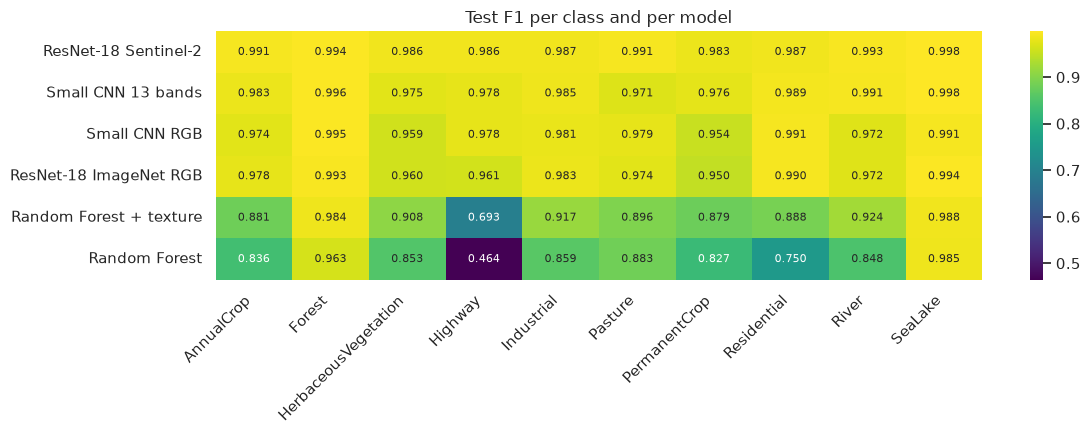

In [15]:
per_class = pd.DataFrame(
    {name: {c: scores(y, pred)[f"f1_{c}"] for c in EUROSAT_CLASSES} for name, (y, pred, _) in test_predictions.items()}
).T.loc[results.index]

plt.figure(figsize=(12, 4.5))
sns.heatmap(per_class, annot=True, fmt=".3f", cmap="viridis", annot_kws={"size": 8})
plt.title("Test F1 per class and per model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_class_f1.png", dpi=150)

In [16]:
def gain(better, baseline):
    return (per_class.loc[better] - per_class.loc[baseline]).sort_values(ascending=False).round(3)


pd.DataFrame(
    {
        "CNN 13 vs RF (spatial pattern, H2)": gain("Small CNN 13 bands", "Random Forest"),
        "RF+texture vs RF (H2)": gain("Random Forest + texture", "Random Forest"),
        "CNN 13 vs CNN RGB (bands, H4)": gain("Small CNN 13 bands", "Small CNN RGB"),
        "ResNet S2 vs CNN 13 (pretraining, H3)": gain("ResNet-18 Sentinel-2", "Small CNN 13 bands"),
    }
)

,"CNN 13 vs RF (spatial pattern, H2)",RF+texture vs RF (H2),"CNN 13 vs CNN RGB (bands, H4)","ResNet S2 vs CNN 13 (pretraining, H3)"
AnnualCrop,0.147,0.045,0.008,0.008
Forest,0.032,0.021,0.001,-0.002
HerbaceousVegetation,0.122,0.054,0.016,0.011
Highway,0.514,0.229,-0.000,0.008
Industrial,0.126,0.058,0.004,0.002
Pasture,0.087,0.012,-0.008,0.020
PermanentCrop,0.150,0.052,0.023,0.007
Residential,0.239,0.138,-0.002,-0.002
River,0.143,0.076,0.018,0.003
SeaLake,0.013,0.002,0.007,-0.001


**What it shows**

- Pixels against averages (CNN against Random Forest): Highway (+0.51) and Residential (+0.24) gain most;
  Forest and SeaLake, already separated by colour, barely change.
- 13 bands against RGB: gains on PermanentCrop, River and HerbaceousVegetation; Pasture does not gain.
- Hardest classes for the best model: PermanentCrop, HerbaceousVegetation and Highway (F1 0.983 to 0.986).

### Confusion matrix of the best model

,true,predicted,count
0,PermanentCrop,HerbaceousVegetation,5
1,HerbaceousVegetation,PermanentCrop,4
2,Industrial,Residential,4
3,AnnualCrop,PermanentCrop,3
4,Forest,HerbaceousVegetation,3
5,Highway,Residential,3
6,Pasture,Forest,3
7,PermanentCrop,AnnualCrop,3


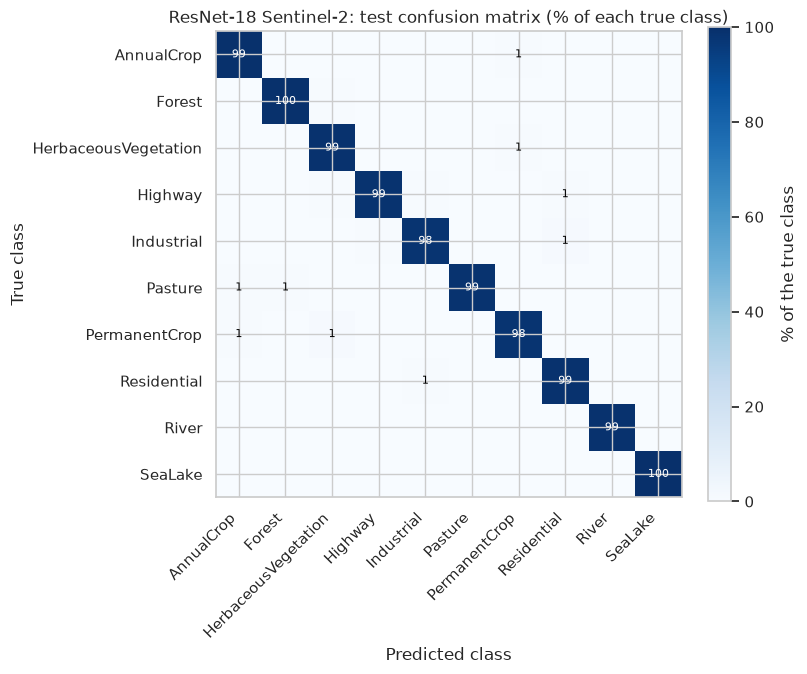

In [17]:
best_name = results.index[0]
y, pred, probs = test_predictions[best_name]
plot_confusion_matrix(y, pred, title=f"{best_name}: test confusion matrix (% of each true class)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=150)
top_confusions(y, pred)

**What it shows**

- 55 errors on 5,400 tiles, in two groups: agricultural vegetation (HerbaceousVegetation and PermanentCrop
  above all) and built-up classes (Industrial, Residential, Highway).

### The most confident errors

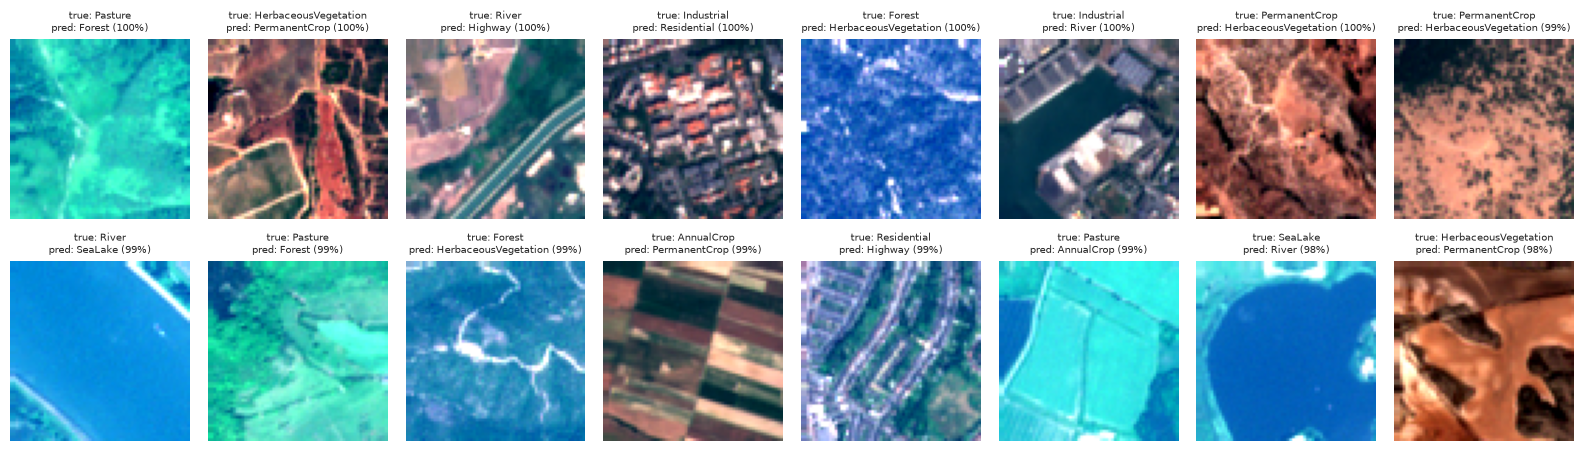

In [18]:
test_ds = eurosat("test")  # file order: to_rgb's default
errors = np.flatnonzero(pred != y)
most_confident = errors[np.argsort(-probs[errors].max(axis=1))][:16]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax, idx in zip(axes.flat, most_confident):
    ax.imshow(to_rgb(test_ds[idx]["image"]))
    ax.set_title(
        f"true: {EUROSAT_CLASSES[y[idx]]}\npred: {EUROSAT_CLASSES[pred[idx]]} ({probs[idx].max():.0%})", fontsize=7
    )
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confident_errors.png", dpi=150)

**What it shows**

- Several look mislabelled (a "River" tile with no visible water) or mixed (pasture with patches of forest).
- All 16 have a probability of 98 % or more: high confidence does not guarantee a right answer.
- At 99 % accuracy, part of the remaining error is label noise.

## 7. Hypotheses: verdict

| ID | Hypothesis | Evidence | Verdict |
|---|---|---|---|
| H1 | Tile averages separate most classes. | Random Forest 83.7 %; F1 ≥ 0.82 on 8 classes, Highway 0.46 | **Confirmed** for 8 of 10 classes |
| H2 | Texture matters most for shape classes. | CNN gain: Highway +0.51, Residential +0.24, Forest +0.03 | **Confirmed** |
| H3 | Sentinel-2 pretraining helps. | +0.5 points (p = 0.003); 96 % after one epoch | **Confirmed**, smaller than guessed; much faster training |
| H4 | Extra bands help, mostly on vegetation. | +0.7 points (p = 0.001); PermanentCrop, HerbaceousVegetation | **Mostly confirmed**, smaller than guessed |
| H5 | Errors concentrate on agricultural classes. | 33 of 55 errors | **Partly**: built-up classes form a second group |

## 8. What may have affected these results

- **One run per model:** the 0.5 and 0.7-point gains may change with other random seeds.
- **Settings not tuned per model, best epochs at the very end:** each model may be below its best.
- **64 × 64 inputs** for ResNets pretrained on 224 × 224 images probably underestimate them.
- **Mislabelled test tiles** cap the measurable accuracy.
- **EuroSAT is optimistic:** random (not spatial) split, single-class tiles, Level-1C only. Notebook 3
  measures the real-world gap.
- **Possible shortcut** through the atmospheric bands B09 and B10, seen in the Random Forest; untested for
  the deep models.

## 9. Export for the API

The best ResNet is saved with its class names, band order and normalisation, the format the API loads.

In [19]:
best_resnet = next(name for name in results.index if name.startswith("ResNet"))
lit = models[best_resnet]
bundle = {
    "arch": "resnet18",
    "state_dict": {k: v.cpu() for k, v in lit.net.state_dict().items()},
    "classes": EUROSAT_CLASSES,
    "bands": RGB_BANDS if "RGB" in best_resnet else BANDS_BY_WAVELENGTH,
    "mean": lit.mean.flatten().tolist(),
    "std": lit.std.flatten().tolist(),
}
bundle_path = MODELS_DIR / "eurosat_resnet18.pt"
torch.save(bundle, bundle_path)
print(f"Exported {best_resnet} to {bundle_path}")

Exported ResNet-18 Sentinel-2 to /home/moha/agri_sentinel_ai/models/eurosat_resnet18.pt


**Check:** the API's loading code gives the same prediction as the notebook.

In [20]:
sys.path.insert(0, str(ROOT))
from api.main import INPUT_BANDS, load_bundle  # noqa: E402

api_bundle = load_bundle(bundle_path)
tile = test_ds[0]["image"]  # file order, as the API receives it
x = tile[api_bundle["band_indices"]]
x = (x - api_bundle["mean"]) / api_bundle["std"]
with torch.inference_mode():
    api_probs = torch.softmax(api_bundle["model"](x.unsqueeze(0)), dim=1)[0].numpy()

notebook_probs = test_predictions[best_resnet][2][0]
# The GPU uses faster, slightly less precise maths (TF32) than the CPU: allow small differences.
assert INPUT_BANDS == EUROSAT_BANDS
assert api_probs.argmax() == notebook_probs.argmax()
assert np.allclose(api_probs, notebook_probs, atol=1e-2), (api_probs, notebook_probs)
print("API and notebook agree:", EUROSAT_CLASSES[api_probs.argmax()])

API and notebook agree: AnnualCrop


## 10. Conclusion

A ResNet-18 pretrained on Sentinel-2 reaches 98.98 % on EuroSAT. Most of the gain comes from the spatial
pattern; extra bands and pretraining add smaller, statistically clear gains. These scores describe EuroSAT,
not any Sentinel-2 image: [notebook 3](03_eurosat_real_world.ipynb) tests the model on new 2025 images.

**Next steps:** two more seeds per model; a small CNN without B09 and B10; fine-tuning on larger tiles
(128 × 128).